# Which Tool Solves Which Problem?

Graph theory, KCL/KVL, a compiler, the Laplace transform and
probability algebra are usually taught in five different courses. This
notebook runs one thread through all of them — an electric circuit —
and introduces each tool by the problem it removes.

| Part | Tool | The problem it solves |
|---|---|---|
| 1 | Graph theory | *How many* independent equations does a circuit need? |
| 2 | KCL and KVL | *Which* equations? (They are conservation of charge and of energy.) |
| 3 | A netlist compiler | *Who writes them?* Turn a text description into equations automatically. |
| 4 | Laplace transform | *What about time?* Turn differential equations into algebra. |
| 5 | Probability algebra on logic | *How often* is a digital output 1 — and what does that cost in power? |

Everything is exact SymPy algebra, and every claim is asserted in the
cell that makes it.

In [1]:
import itertools
import re

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib.patches import FancyArrowPatch
from scipy import signal
from sympy import Matrix, Rational, symbols

s = sp.Symbol('s')                       # Laplace variable
t = sp.Symbol('t', positive=True)        # time
print("sympy", sp.__version__)

sympy 1.14.0


# Part 1 — Graph theory: how many equations?

Strip a circuit of its component values and what remains is a **graph**:
nodes (junctions) joined by branches (components). Give each branch an
arrow for its reference current direction.

The whole wiring diagram fits in one matrix. The **incidence matrix**
$A$ has a row per node and a column per branch:
$+1$ where the branch leaves the node, $-1$ where it enters, $0$
otherwise.

The example throughout Parts 1–3 is the **Wheatstone bridge**: a source
and five resistors on four nodes.

columns: ['Vs', 'R1', 'R2', 'R3', 'R4', 'R5']
⎡-1  0   -1  0   -1  0 ⎤
⎢                      ⎥
⎢1   1   0   1   0   0 ⎥
⎢                      ⎥
⎢0   -1  1   0   0   1 ⎥
⎢                      ⎥
⎣0   0   0   -1  1   -1⎦


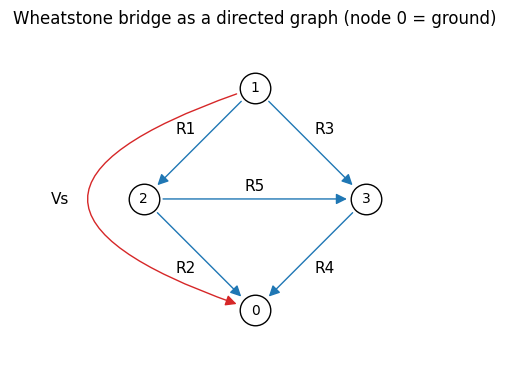

In [2]:
branches = [("Vs", 1, 0), ("R1", 1, 2), ("R2", 2, 0), ("R3", 1, 3), ("R4", 3, 0), ("R5", 2, 3)]
names = [name for name, _, _ in branches]
n_nodes = 4


def incidence_matrix(branch_list, node_count):
    A = sp.zeros(node_count, len(branch_list))
    for k, (_, leaves, enters) in enumerate(branch_list):
        A[leaves, k] = 1
        A[enters, k] = -1
    return A


A = incidence_matrix(branches, n_nodes)
print("columns:", names)
sp.pprint(A)

position = {0: (0, -1), 1: (0, 1), 2: (-1, 0), 3: (1, 0)}
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for name, a_node, b_node in branches:
    start, end = position[a_node], position[b_node]
    bend = 1.5 if name == "Vs" else 0.0
    ax.add_patch(FancyArrowPatch(start, end, connectionstyle=f"arc3,rad={bend}", arrowstyle="-|>",
                                 mutation_scale=16, shrinkA=14, shrinkB=14,
                                 color="C3" if name == "Vs" else "C0"))
    middle = ((start[0] + end[0]) / 2, (start[1] + end[1]) / 2)
    label_at = (-1.75, 0.0) if name == "Vs" else (middle[0] * 1.25, middle[1] * 1.25 + (0.12 if name == "R5" else 0))
    ax.text(*label_at, name, ha="center", va="center", fontsize=11)
for node, (px, py) in position.items():
    ax.plot(px, py, "o", ms=22, mfc="white", mec="k")
    ax.text(px, py, str(node), ha="center", va="center")
ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Wheatstone bridge as a directed graph (node 0 = ground)")
plt.tight_layout(); plt.show()

Linear algebra on $A$ now answers the counting question.

- Every column has one $+1$ and one $-1$, so the rows add to zero: one
  node equation is redundant. A connected graph with $n$ nodes gives
  **$n - 1$ independent node equations** (the rank of $A$).
- The vectors $x$ with $Ax = 0$ are the **loops**: sets of branches
  that enter every node as often as they leave it. There are
  **$b - n + 1$ independent loops**.

For the bridge: $b = 6$, $n = 4$, so 3 node equations and 3 loops.

In [3]:
rank = A.rank()
loops = A.nullspace()
print(f"branches b = {len(branches)}, nodes n = {n_nodes}")
print(f"independent node equations = rank(A) = {rank}")
print(f"independent loops = b - n + 1 = {len(loops)}\n")
for loop in loops:
    path = " ".join(("+" if entry > 0 else "-") + name for entry, name in zip(loop, names) if entry != 0)
    print("loop:", path)

assert rank == n_nodes - 1 and len(loops) == len(branches) - n_nodes + 1
assert all(entry in (-1, 0, 1) for loop in loops for entry in loop)

branches b = 6, nodes n = 4
independent node equations = rank(A) = 3
independent loops = b - n + 1 = 3

loop: -Vs +R1 +R2
loop: -Vs +R3 +R4
loop: +R1 -R3 +R5


# Part 2 — KCL and KVL: which equations?

The two circuit laws are two conservation laws, and both are one line
with the incidence matrix.

| Law | Statement | Physics behind it | In matrix form |
|---|---|---|---|
| **KCL** | currents leaving a node sum to zero | charge is conserved (nothing piles up at a junction) | $A\,i = 0$ |
| **KVL** | voltages around a loop sum to zero | the electrostatic field is conservative (a potential exists) | $v = A^{\mathsf T} e$ |

Here $i$ holds the branch currents, $v$ the branch voltages and $e$ the
node potentials. Writing each branch voltage as a *difference of node
potentials* makes KVL automatic — the sum around any loop telescopes to
zero. $A$ acts as a discrete divergence and $A^{\mathsf T}$ as a
discrete gradient.

A consequence that needs no component values at all is **Tellegen's
theorem**: $\sum_k v_k i_k = 0$. Power delivered equals power absorbed,
in any circuit, purely because of how it is wired.

In [4]:
e = Matrix(symbols("e0:4"))                         # arbitrary node potentials
v = A.T * e                                           # branch voltages (KVL built in)
for loop in loops:
    assert sp.expand((loop.T * v)[0]) == 0            # voltages around every loop sum to zero
print("KVL holds around all", len(loops), "loops for ANY node potentials")

coefficients = symbols("j1:4")                        # arbitrary loop currents
i = sum((c * loop for c, loop in zip(coefficients, loops)), sp.zeros(len(branches), 1))
assert A * i == sp.zeros(n_nodes, 1)                  # KCL holds at every node
tellegen = sp.expand((v.T * i)[0])
print("KCL holds at all", n_nodes, "nodes for ANY combination of loop currents")
print("Tellegen: sum of v_k * i_k =", tellegen)
assert tellegen == 0

KVL holds around all 3 loops for ANY node potentials
KCL holds at all 4 nodes for ANY combination of loop currents
Tellegen: sum of v_k * i_k = 0


## Adding the components: nodal analysis by hand

The laws say nothing about resistors. Add Ohm's law ($i = v/R$) and KCL
becomes a set of equations for the node potentials. Node 1 is held at
$V_s$ by the source, so only nodes 2 and 3 need an equation:

$$\frac{e_2 - V_s}{R_1} + \frac{e_2}{R_2} + \frac{e_2 - e_3}{R_5} = 0, \qquad
\frac{e_3 - V_s}{R_3} + \frac{e_3}{R_4} + \frac{e_3 - e_2}{R_5} = 0 .$$

The quantity of interest is the current through the middle resistor,
$i_5 = (e_2 - e_3)/R_5$.

In [5]:
R1, R2, R3, R4, R5, Vs = symbols("R1 R2 R3 R4 R5 Vs", positive=True)
e2, e3 = symbols("e2 e3")

kcl = [(e2 - Vs) / R1 + e2 / R2 + (e2 - e3) / R5,
       (e3 - Vs) / R3 + e3 / R4 + (e3 - e2) / R5]
solution = sp.solve(kcl, [e2, e3], dict=True)[0]
i5_by_hand = sp.factor((solution[e2] - solution[e3]) / R5)
print("i5 ="); sp.pprint(i5_by_hand)

# the bridge is balanced -- no current in R5 -- exactly when R1/R2 = R3/R4
assert sp.simplify(i5_by_hand.subs(R4, R2 * R3 / R1)) == 0
print("\ni5 = 0 when R1/R2 = R3/R4  (the balance condition)")

i5 =


                                -Vs⋅(R₁⋅R₄ - R₂⋅R₃)                            ↪
────────────────────────────────────────────────────────────────────────────── ↪
R₁⋅R₂⋅R₃ + R₁⋅R₂⋅R₄ + R₁⋅R₃⋅R₄ + R₁⋅R₃⋅R₅ + R₁⋅R₄⋅R₅ + R₂⋅R₃⋅R₄ + R₂⋅R₃⋅R₅ + R ↪

↪        
↪ ───────
↪ ₂⋅R₄⋅R₅

i5 = 0 when R1/R2 = R3/R4  (the balance condition)


The numerator is $R_2R_3 - R_1R_4$: the detector current vanishes when
$R_1/R_2 = R_3/R_4$, whatever $R_5$ and $V_s$ are. That is why a bridge
measures an unknown resistance so precisely — it is a null measurement.

Two equations were manageable. Twenty would not be, and every new
circuit means writing them again. That is the next problem.

# Part 3 — A netlist compiler: who writes the equations?

A **compiler** translates a description written for people into a form
a machine can execute. Circuit simulators are compilers: the input
language is a **netlist** (one line per component: name, two nodes,
value) and the output is a matrix equation.

| Compiler stage | Here |
|---|---|
| **Lexing** — split text into tokens | split lines into words, drop comments |
| **Parsing** — check the grammar, build a structure | each line must be `name node node value`; the first letter gives the type |
| **Diagnostics** — reject bad programs with a useful message | unknown component, wrong field count, missing ground, with line numbers |
| **Code generation** — emit the target form | "stamp" each component into a matrix (modified nodal analysis) |
| **Back end** — run it | solve the linear system symbolically |

Each component type contributes a fixed pattern to the matrix. A
resistor between nodes $a$ and $b$ adds its conductance $1/R$ at
$(a,a)$ and $(b,b)$ and subtracts it at $(a,b)$ and $(b,a)$ — which is
KCL plus Ohm's law, written once and reused for every resistor.
Capacitors and inductors are stamped as $sC$ and $1/(sL)$, which
Part 4 explains.

In [6]:
class NetlistError(Exception):
    pass


SUFFIX = {"meg": 10**6, "k": 10**3, "m": Rational(1, 10**3), "u": Rational(1, 10**6),
          "n": Rational(1, 10**9), "p": Rational(1, 10**12)}


def tokenize(source):
    # lexing: (line number, list of words); '*' or '#' starts a comment
    lines = []
    for number, raw in enumerate(source.splitlines(), start=1):
        text = re.split(r"[*#]", raw)[0].strip()
        if text:
            lines.append((number, text.split()))
    return lines


def parse_value(text, line_number):
    # '4.7k' -> 4700 exactly; 'R' -> a positive symbol
    match = re.fullmatch(r"(\d+(?:\.\d+)?)(meg|k|m|u|n|p)?", text.lower())
    if match:
        return Rational(match.group(1)) * SUFFIX.get(match.group(2), 1)
    if re.fullmatch(r"[A-Za-z_]\w*", text):
        return sp.Symbol(text, positive=True)
    raise NetlistError(f"line {line_number}: cannot read value {text!r}")


def parse(source):
    # parsing: every line must be  name  node  node  value
    elements, seen = [], set()
    for number, words in tokenize(source):
        if len(words) != 4:
            raise NetlistError(f"line {number}: expected 'name node node value', got {len(words)} fields")
        name, node_a, node_b, value = words
        kind = name[0].upper()
        if kind not in "RCLVI":
            raise NetlistError(f"line {number}: unknown component type {name[0]!r} (use R, C, L, V or I)")
        if name in seen:
            raise NetlistError(f"line {number}: component {name!r} is defined twice")
        seen.add(name)
        elements.append({"name": name, "kind": kind, "a": node_a, "b": node_b,
                         "value": parse_value(value, number)})
    if not any("0" in (el["a"], el["b"]) for el in elements):
        raise NetlistError("no component touches node '0': the circuit has no ground reference")
    return elements


def compile_netlist(source):
    # code generation: build the modified-nodal-analysis system  M x = z
    elements = parse(source)
    nodes = []
    for el in elements:
        for node in (el["a"], el["b"]):
            if node != "0" and node not in nodes:
                nodes.append(node)
    sources = [el for el in elements if el["kind"] == "V"]
    size = len(nodes) + len(sources)
    M, z = sp.zeros(size, size), sp.zeros(size, 1)
    row = {node: k for k, node in enumerate(nodes)}

    for el in elements:
        a, b, value = el["a"], el["b"], el["value"]
        if el["kind"] in "RCL":
            admittance = {"R": 1 / value, "C": s * value, "L": 1 / (s * value)}[el["kind"]]
            for p, q in ((a, a), (b, b)):
                if p != "0":
                    M[row[p], row[q]] += admittance
            if a != "0" and b != "0":
                M[row[a], row[b]] -= admittance
                M[row[b], row[a]] -= admittance
        elif el["kind"] == "I":                       # current flows from a, through the source, to b
            if a != "0":
                z[row[a]] -= value
            if b != "0":
                z[row[b]] += value
        else:                                         # voltage source: one extra unknown, its current
            extra = len(nodes) + sources.index(el)
            if a != "0":
                M[row[a], extra] += 1; M[extra, row[a]] += 1
            if b != "0":
                M[row[b], extra] -= 1; M[extra, row[b]] -= 1
            z[extra] = value
    unknowns = [f"v({node})" for node in nodes] + [f"i({el['name']})" for el in sources]
    return {"matrix": M, "rhs": z, "unknowns": unknowns, "nodes": nodes}


def solve_netlist(source):
    # back end: solve and tidy
    program = compile_netlist(source)
    values = program["matrix"].LUsolve(program["rhs"])
    return {name: sp.factor(sp.cancel(value)) for name, value in zip(program["unknowns"], values)}


bridge = '''
* Wheatstone bridge
V1 1 0 Vs
R1 1 2 R1
R2 2 0 R2
R3 1 3 R3      # the two arms
R4 3 0 R4
R5 2 3 R5      * the detector
'''
print("tokens:", tokenize(bridge)[:2], "...")
program = compile_netlist(bridge)
print("unknowns:", program["unknowns"])
sp.pprint(program["matrix"])

tokens: [(3, ['V1', '1', '0', 'Vs']), (4, ['R1', '1', '2', 'R1'])] ...
unknowns: ['v(1)', 'v(2)', 'v(3)', 'i(V1)']
⎡1    1       -1            -1         ⎤
⎢── + ──      ───           ───       1⎥
⎢R₃   R₁      R₁            R₃         ⎥
⎢                                      ⎥
⎢  -1     1    1    1       -1         ⎥
⎢  ───    ── + ── + ──      ───       0⎥
⎢  R₁     R₅   R₂   R₁      R₅         ⎥
⎢                                      ⎥
⎢  -1         -1        1    1    1    ⎥
⎢  ───        ───       ── + ── + ──  0⎥
⎢  R₃         R₅        R₅   R₄   R₃   ⎥
⎢                                      ⎥
⎣   1          0             0        0⎦


The compiled result must agree with the hand analysis — and the top
left block of the matrix should be exactly what graph theory predicts:
$A_r\,Y\,A_r^{\mathsf T}$, where $A_r$ is the incidence matrix of the
resistor branches with the ground row removed and $Y$ is the diagonal
matrix of conductances.

In [7]:
answers = solve_netlist(bridge)
i5_compiled = sp.factor((answers["v(2)"] - answers["v(3)"]) / R5)
assert sp.simplify(i5_compiled - i5_by_hand) == 0
print("compiler and hand analysis agree on i5")

resistor_branches = [branch for branch in branches if branch[0] != "Vs"]
A_r = incidence_matrix(resistor_branches, n_nodes)[1:, :]          # drop the ground row
Y = sp.diag(1 / R1, 1 / R2, 1 / R3, 1 / R4, 1 / R5)
assert (A_r * Y * A_r.T - program["matrix"][:3, :3]).applyfunc(sp.simplify) == sp.zeros(3)
print("node block of the compiled matrix  ==  A_r * Y * A_r^T")

# with every resistor equal to 1 ohm this is the graph Laplacian (degree on the diagonal)
print("\nall resistors 1 ohm:"); sp.pprint(A_r * A_r.T)

compiler and hand analysis agree on i5
node block of the compiled matrix  ==  A_r * Y * A_r^T

all resistors 1 ohm:
⎡2   -1  -1⎤
⎢          ⎥
⎢-1  3   -1⎥
⎢          ⎥
⎣-1  -1  3 ⎦


With unit resistors the matrix is the **graph Laplacian**: each
diagonal entry counts the branches at a node, each off-diagonal entry
is $-1$ where two nodes are joined. The same matrix drives diffusion on
networks and the message passing in graph neural networks.

A compiler is also judged by what it refuses. Three broken netlists:

In [8]:
broken = {
    "unknown component": "V1 1 0 5\nX1 1 0 1k",
    "wrong field count": "V1 1 0 5\nR1 1 0",
    "no ground":         "V1 1 2 5\nR1 1 2 1k",
}
for label, text in broken.items():
    try:
        solve_netlist(text)
        raise AssertionError("should have been rejected")
    except NetlistError as problem:
        print(f"{label:18s} -> {problem}")

# and a numeric circuit: a 10 V source across a 1k / 4.7k divider
divider = solve_netlist("V1 in 0 10\nR1 in out 1k\nR2 out 0 4.7k")
print("\ndivider output:", divider["v(out)"], "V =", float(divider["v(out)"]), "V")
assert divider["v(out)"] == Rational(470, 57)

unknown component  -> line 2: unknown component type 'X' (use R, C, L, V or I)
wrong field count  -> line 2: expected 'name node node value', got 3 fields
no ground          -> no component touches node '0': the circuit has no ground reference

divider output: 470/57 V = 8.24561403508772 V


# Part 4 — The Laplace transform: what about time?

Capacitors and inductors obey *differential* laws,
$i = C\,dv/dt$ and $v = L\,di/dt$. A circuit containing them is
described by differential equations, and the matrix method above seems
to break.

The **Laplace transform** repairs it. It trades a function of time
$f(t)$ for a function $F(s)$, and under that trade (with zero initial
conditions) **differentiation becomes multiplication by $s$**. So

$$i = C\frac{dv}{dt} \;\to\; I = sC\,V, \qquad v = L\frac{di}{dt} \;\to\; V = sL\,I,$$

and a capacitor behaves like a "resistor" of value $1/(sC)$, an
inductor like $sL$. Every tool from Parts 1–3 carries over unchanged —
the compiler already stamps them this way.

**Worked example: RC low-pass filter.**

In [9]:
R, C, L, Vin = symbols("R C L Vin", positive=True)

rc = solve_netlist('''
V1 in 0 Vin
R1 in out R
C1 out 0 C
''')
H_rc = sp.cancel(rc["v(out)"] / Vin)
print("transfer function H(s) = Vout/Vin ="); sp.pprint(H_rc)
assert sp.simplify(H_rc - 1 / (1 + s * R * C)) == 0

# step response: multiply by 1/s (the transform of a unit step) and transform back
step_rc = sp.simplify(sp.inverse_laplace_transform(H_rc / s, s, t))
print("\nstep response v_out(t) ="); sp.pprint(step_rc)

# check against solving the differential equation  RC v' + v = 1,  v(0) = 0  directly
v_out = sp.Function("v")
ode = sp.dsolve(R * C * v_out(t).diff(t) + v_out(t) - 1, v_out(t), ics={v_out(0): 0})
assert sp.simplify(step_rc - ode.rhs) == 0
print("\nmatches the solution of the differential equation")

transfer function H(s) = Vout/Vin =
    1    
─────────
C⋅R⋅s + 1

step response v_out(t) =
     -t 
     ───
     C⋅R
1 - ℯ   

matches the solution of the differential equation


The same three lines of netlist would have needed a differential
equation solved by hand. Now a second-order circuit, the series RLC,
where the answer depends on where the **poles** (roots of the
denominator of $H$) sit:

- complex poles → the output rings (underdamped);
- a repeated real pole → fastest response without ringing (critically damped);
- two distinct real poles → sluggish (overdamped).

All poles have negative real part, so every response settles: the
circuit is stable.

H(s) =
        1         
──────────────────
     2            
C⋅L⋅s  + C⋅R⋅s + 1


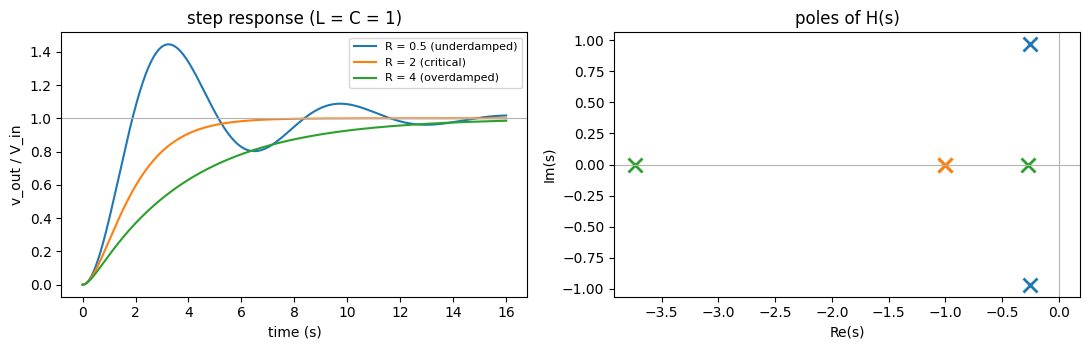

In [10]:
rlc = solve_netlist('''
V1 in 0 Vin
R1 in a R
L1 a out L
C1 out 0 C
''')
H_rlc = sp.cancel(rlc["v(out)"] / Vin)
print("H(s) ="); sp.pprint(H_rlc)
assert sp.simplify(H_rlc - 1 / (L * C * s**2 + R * C * s + 1)) == 0
assert sp.limit(H_rlc, s, 0) == 1          # final-value theorem: a unit step settles at 1

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
time = np.linspace(0, 16, 600)
for resistance, label in [(Rational(1, 2), "R = 0.5 (underdamped)"), (2, "R = 2 (critical)"),
                          (4, "R = 4 (overdamped)")]:
    numeric = H_rlc.subs({L: 1, C: 1, R: resistance})
    numerator, denominator = sp.fraction(sp.cancel(numeric))
    num = [float(c) for c in sp.Poly(numerator, s).all_coeffs()]
    den = [float(c) for c in sp.Poly(denominator, s).all_coeffs()]
    poles = np.roots(den)
    assert np.all(poles.real < 0)          # stable
    _, response = signal.step((num, den), T=time)
    line, = axes[0].plot(time, response, label=label)
    axes[1].plot(poles.real, poles.imag, "x", ms=10, mew=2, color=line.get_color(), label=label)
axes[0].axhline(1, color="0.7", lw=0.8)
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("v_out / V_in"); axes[0].set_title("step response (L = C = 1)")
axes[0].legend(fontsize=8)
axes[1].axvline(0, color="0.7", lw=0.8); axes[1].axhline(0, color="0.7", lw=0.8)
axes[1].set_xlabel("Re(s)"); axes[1].set_ylabel("Im(s)"); axes[1].set_title("poles of H(s)")
plt.tight_layout(); plt.show()

# Part 5 — Probability algebra on digital logic

A logic circuit is also a graph — a directed one with no loops — and it
raises a different question: if each input is 1 with some probability,
**how often is the output 1?** That number, the *signal probability*,
sets how often the gate switches and therefore how much power it burns.

## Turning Boolean algebra into ordinary algebra

Treat each logic value as the number 0 or 1. Then

| Gate | As arithmetic |
|---|---|
| NOT $a$ | $1 - a$ |
| $a$ AND $b$ | $ab$ |
| $a$ OR $b$ | $a + b - ab$ |
| $a$ XOR $b$ | $a + b - 2ab$ |

with one extra rule: **$a^2 = a$**, because $0^2 = 0$ and $1^2 = 1$.

After applying that rule the polynomial has no powers (it is
*multilinear*), and for independent inputs its average value is found
by simply replacing each variable with its probability.

The $a^2 = a$ rule is not a technicality. Without it you get the
classic mistake of treating two signals as independent when they share
an input.

In [11]:
from sympy.logic.boolalg import And, Not, Or, Xor


def raw_arithmetic(expr):
    # gate-by-gate translation, no simplification
    if isinstance(expr, sp.Symbol):
        return expr
    parts = [raw_arithmetic(arg) for arg in expr.args]
    if isinstance(expr, Not):
        return 1 - parts[0]
    if isinstance(expr, And):
        return sp.Mul(*parts)
    if isinstance(expr, Or):
        return 1 - sp.Mul(*[1 - part for part in parts])
    if isinstance(expr, Xor):
        total = parts[0]
        for part in parts[1:]:
            total = total + part - 2 * total * part
        return total
    raise TypeError(f"unsupported gate: {type(expr).__name__}")


def arithmetize(expr):
    # the multilinear polynomial: expand, then apply a**k -> a
    expanded = sp.expand(raw_arithmetic(expr))
    is_power = lambda term: term.is_Pow and term.base.is_Symbol and term.exp.is_Integer and term.exp > 1
    return sp.expand(expanded.replace(is_power, lambda term: term.base))


def exact_probability(expr, probabilities):
    # ground truth: add up the probability of every input combination that makes expr true
    variables = list(probabilities)
    total = 0
    for values in itertools.product([0, 1], repeat=len(variables)):
        if expr.subs({var: bool(val) for var, val in zip(variables, values)}) == True:
            weight = 1
            for var, val in zip(variables, values):
                weight *= probabilities[var] if val else 1 - probabilities[var]
            total += weight
    return sp.expand(total)


a, b, c = symbols("a b c")
pa, pb, pc = symbols("p_a p_b p_c", positive=True)
prob = {a: pa, b: pb, c: pc}

f = Or(And(a, b), And(a, c))                     # the two AND gates share input a
naive = sp.expand(raw_arithmetic(f)).subs(prob)  # pretends the AND outputs are independent
correct = arithmetize(f).subs(prob)
print("f = (a AND b) OR (a AND c)")
print("naive   :", naive)
print("correct :", correct)
half = {pa: Rational(1, 2), pb: Rational(1, 2), pc: Rational(1, 2)}
print(f"at p = 1/2:  naive {naive.subs(half)},  correct {correct.subs(half)}")
assert sp.expand(correct - exact_probability(f, prob)) == 0
assert sp.expand(naive - exact_probability(f, prob)) != 0

f = (a AND b) OR (a AND c)
naive   : -p_a**2*p_b*p_c + p_a*p_b + p_a*p_c
correct : -p_a*p_b*p_c + p_a*p_b + p_a*p_c
at p = 1/2:  naive 7/16,  correct 3/8


The naive answer contains $p_a^2$; the correct one has $p_a$ in its
place. The check against brute-force enumeration is symbolic, so it
holds for every choice of probabilities.

**Worked example: the full adder.** Sum $= a \oplus b \oplus c$ and
carry $=$ "at least two of the three are 1".

In [12]:
sum_bit = Xor(a, b, c)
carry = Or(And(a, b), And(a, c), And(b, c))

for label, gate in [("sum", sum_bit), ("carry", carry)]:
    polynomial = arithmetize(gate)
    assert sp.expand(polynomial.subs(prob) - exact_probability(gate, prob)) == 0
    print(f"{label:5s} = {polynomial}")
    print(f"        P({label} = 1) at p = 1/2: {polynomial.subs(prob).subs(half)}")

# conditional probability with the same algebra:  P(a = 1 | carry = 1) = P(a AND carry) / P(carry)
joint = arithmetize(And(a, carry)).subs(prob).subs(half)
given = joint / arithmetize(carry).subs(prob).subs(half)
print("\nP(a = 1 | carry = 1) =", given)
assert given == Rational(3, 4)

sum   = 4*a*b*c - 2*a*b - 2*a*c + a - 2*b*c + b + c
        P(sum = 1) at p = 1/2: 1/2
carry = -2*a*b*c + a*b + a*c + b*c
        P(carry = 1) at p = 1/2: 1/2

P(a = 1 | carry = 1) = 3/4


Seeing a carry makes it more likely (3/4, up from 1/2) that any
particular input was 1 — Bayes' rule, done by polynomial arithmetic.

## Why a chip designer cares: switching power

A gate's output drives a small capacitance $C$. Each time the output
goes from 0 to 1 the supply delivers energy $CV^2$: half ends up stored
on the capacitor and half is lost as heat in the charging resistance —
**whatever that resistance is**. That is the RC circuit of Part 4.

In [13]:
V = symbols("V", positive=True)
current = V / R * sp.exp(-t / (R * C))                    # charging current of the Part 4 RC circuit
heat = sp.integrate(current**2 * R, (t, 0, sp.oo))        # energy dissipated in R
supplied = sp.integrate(V * current, (t, 0, sp.oo))       # energy delivered by the source
print("heat in the resistor  =", heat)
print("energy from the supply =", supplied)
assert sp.simplify(heat - C * V**2 / 2) == 0 and sp.simplify(supplied - C * V**2) == 0

heat in the resistor  = C*V**2/2
energy from the supply = C*V**2


If successive clock cycles are independent, the chance of a 0 → 1
transition is $\alpha = (1 - p)\,p$, and the average dynamic power is

$$P = \alpha\, C V^2 f .$$

gate               P(out = 1) at p = 1/2    alpha    power at C = 1 fF, V = 1 V, f = 1 GHz
AND                       1/4                3/16    0.1875 uW
OR                        3/4                3/16    0.1875 uW
XOR                       1/2                 1/4    0.2500 uW
full-adder carry          1/2                 1/4    0.2500 uW


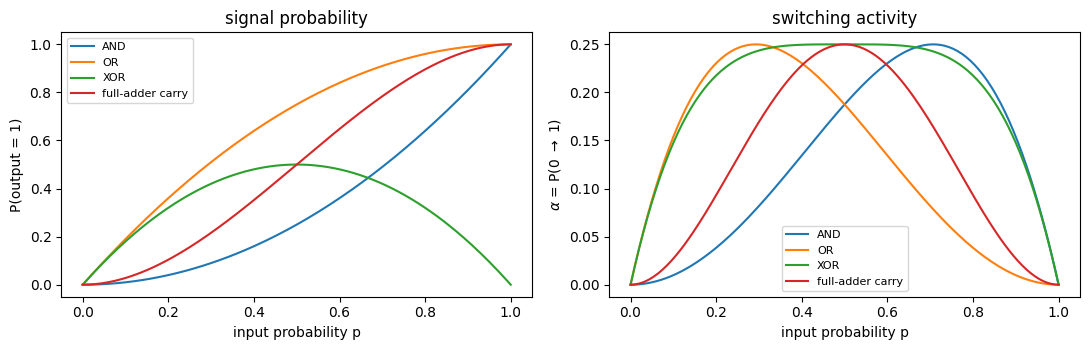

In [14]:
p = symbols("p", positive=True)
same = {pa: p, pb: p, pc: p}
gates = {"AND": And(a, b), "OR": Or(a, b), "XOR": Xor(a, b), "full-adder carry": carry}

print("gate               P(out = 1) at p = 1/2    alpha    power at C = 1 fF, V = 1 V, f = 1 GHz")
pp = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for label, gate in gates.items():
    p_out = arithmetize(gate).subs(prob).subs(same)
    alpha = sp.expand((1 - p_out) * p_out)
    at_half = p_out.subs(p, Rational(1, 2))
    alpha_half = alpha.subs(p, Rational(1, 2))
    power_w = float(alpha_half) * 1e-15 * 1.0**2 * 1e9
    print(f"{label:18s} {str(at_half):>10s} {str(alpha_half):>19s}    {power_w * 1e6:.4f} uW")
    axes[0].plot(pp, sp.lambdify(p, p_out, "numpy")(pp), label=label)
    axes[1].plot(pp, sp.lambdify(p, alpha, "numpy")(pp), label=label)
axes[0].set_xlabel("input probability p"); axes[0].set_ylabel("P(output = 1)"); axes[0].legend(fontsize=8)
axes[0].set_title("signal probability")
axes[1].set_xlabel("input probability p"); axes[1].set_ylabel(r"$\alpha$ = P(0 $\to$ 1)")
axes[1].set_title("switching activity"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

assert arithmetize(And(a, b)).subs(prob).subs(half) == Rational(1, 4)
assert arithmetize(Xor(a, b)).subs(prob).subs(half) == Rational(1, 2)

With random inputs an XOR output sits at 1 half the time, the most
active state possible ($\alpha = 1/4$), while an AND output is usually
0 ($\alpha = 3/16$). Arithmetic circuits, which are built from XORs,
switch more than control logic for the same number of gates.

# Summary: which tool solves which problem

| Tool | Problem it solves | Evidence in this notebook |
|---|---|---|
| Incidence matrix (graph theory) | counts the equations: $n-1$ node equations, $b-n+1$ loops | rank and null space of $A$ for the bridge |
| KCL, KVL | supplies the equations: $Ai = 0$, $v = A^{\mathsf T}e$ | Tellegen's theorem follows with no component values |
| Netlist compiler | writes the equations for any circuit, and rejects malformed ones | matches the hand analysis; matrix block equals $A_r Y A_r^{\mathsf T}$ |
| Laplace transform | turns $d/dt$ into multiplication by $s$, so dynamics become algebra | RC step response equals the differential-equation solution |
| Probability algebra | gives signal probability exactly, including shared inputs | multilinear polynomial equals brute-force enumeration |

**What these tools do not solve.** Everything here is *linear*: diodes
and transistors need iteration on top of the same matrices. The
compiler assumes zero initial conditions. The probability algebra
assumes independent *inputs* and no timing effects (glitches add
switching that it does not count).

Related notebooks in this repository:
[`circuit_laplace_dependent_sources.ipynb`](circuit_laplace_dependent_sources.ipynb),
[`sequential_logic.ipynb`](sequential_logic.ipynb) and
[`statics_hw2_sympy.ipynb`](statics_hw2_sympy.ipynb).